In [27]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 
import pickle

from matplotlib import pyplot as plt
from scipy.optimize import least_squares
from random import randint
from itertools import product

import importlib
import functions
import scattering_model
import differential_evolution_routine

importlib.reload(functions)
importlib.reload(scattering_model)
importlib.reload(differential_evolution_routine)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


<module 'differential_evolution_routine' from '/Users/peytaguo/Desktop/ASC/Nucelar Resonance Analysis /differential_evolution_routine.py'>

In [2]:
ne_amu = 19.9869544
a_amu = 4.001506179129

mg_amu = 23.9784588
uc2 = 931.494 #MeV

energy_threshold = (ne_amu + a_amu - mg_amu)*uc2
print(energy_threshold)

9.316597247987401


In [3]:
sigma = np.load("data/peyta_sigma1.npy")
dsigma = np.load("data/peyta_dsigma1.npy")
theta_cm = np.load("data/peyta_theta_cm1.npy")
ke_cm = np.load("data/peyta_ke_cm1.npy")

rounded_theta_cm = np.round(theta_cm, 1)
rounded_theta_cm[rounded_theta_cm == 53.2] = 53.1
rounded_theta_cm[rounded_theta_cm == 143.2] = 143.1
rounded_theta_cm[rounded_theta_cm == 155.7] = 155.8

print( np.unique( rounded_theta_cm ) )
print(len(np.unique(rounded_theta_cm)))

[ 53.1  58.8  70.   75.5  86.2  91.4 101.6 106.5 116.2 125.5 130.  138.8
 143.1 155.8 163.9 168. ]
16


In [4]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma, 9.31)
#functions.visualise_all_peaks(all_cs)

In [5]:
clusters_dp_chosen = functions.get_clusters_dp(all_cs, 0.001, 0.005)

In [6]:
clusters_dp_chosen[0]

[np.float64(13.32186782827972),
 [[58.8, np.float64(13.315620272331726), np.float64(0.48017776796147543)],
  [53.1, np.float64(13.328115384227713), np.float64(0.696244297387564)]]]

In [7]:
cluster_widths = functions.get_cluster_widths(clusters_dp_chosen)

In [ ]:
#functions.get_dp_clusters_info(clusters_dp_chosen)

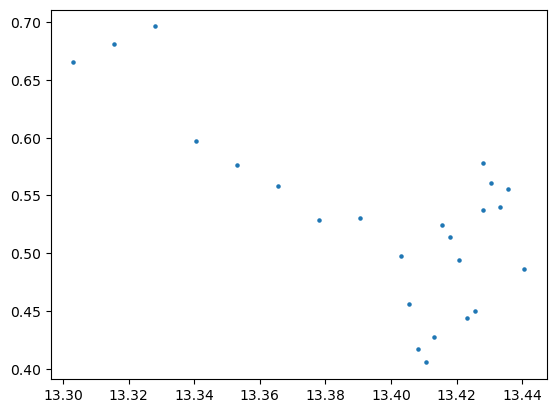

In [8]:
angles = list(all_cs.keys())

#all_cs[angles[0]].keys() -> 'ke', 'sigma', 'dsigma'

sigma_531 = all_cs[angles[0]]['sigma']
ke_531 = all_cs[angles[0]]['ke']

E_min, E_max = 13, 13.45

mask = (ke_531 >= E_min) & (ke_531 <= E_max)

E_window = ke_531[mask]
sigma_window = sigma_531[mask]

plt.scatter(
    E_window, 
    sigma_window,
    s=5
)
plt.show()

In [9]:
cluster_energies = [cluster[0] for cluster in clusters_dp_chosen]
cluster_widths = functions.get_cluster_widths(clusters_dp_chosen)

initial_parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

print(cluster_energies)

[np.float64(13.32186782827972), np.float64(13.379647365167385), np.float64(13.420724960967716), np.float64(13.478503549358422), np.float64(13.554854287229828), np.float64(13.636278844758236), np.float64(13.68791759034153), np.float64(13.731515116522399), np.float64(13.779079089074513), np.float64(13.824890878203005), np.float64(13.863283520137786), np.float64(13.908262928283293), np.float64(14.02283366705244), np.float64(14.059876681221004), np.float64(14.095513128862724), np.float64(14.144741357771649), np.float64(14.170529678049867), np.float64(14.255868680681997), np.float64(14.331302842044678), np.float64(14.390549114451925), np.float64(14.463505344036344), np.float64(14.497741458028996), np.float64(14.548318080561536), np.float64(14.62324668213953), np.float64(14.6578396757273), np.float64(14.69437965149989), np.float64(14.757488310032965), np.float64(14.84187951342079), np.float64(14.88494707406901), np.float64(14.924782404250218), np.float64(14.99110263791823), np.float64(15.064

In [10]:
window = scattering_model.get_window_cs(all_cs, E_min, E_max)

number_of_resonances = int((len(initial_parameters) - 32)/5)

angular_momenta = [randint(0,5) for _ in range(number_of_resonances)]

intial_parameters = scattering_model.get_initial_parameters(
    cluster_energies,
    cluster_widths,
    E_min,
    E_max
)

lower_bound, upper_bound = scattering_model.get_bounds(E_min, E_max, cluster_energies)

initial_res = scattering_model.get_residual(intial_parameters, angular_momenta, window)

#print(initial_res)

In [11]:
print("Initial parameters:", np.shape(initial_parameters))
print("Lower bounds:", np.shape(lower_bound))
print("Upper bounds:", np.shape(upper_bound))

Initial parameters: (137,)
Lower bounds: (137,)
Upper bounds: (137,)


In [ ]:
fits = []

combinations = list(product(range(6), repeat=number_of_resonances))
total = len(combinations)

for i, angular_momenta in enumerate(combinations, start=1):
    fit = least_squares(
    scattering_model.get_residual,
    x0 = intial_parameters,
    args = (angular_momenta, window),
    bounds = (lower_bound, upper_bound),
    max_nfev = 200,
    verbose = 1
)
    fits.append((fit, angular_momenta))

    print(
    f"\rProgress: {100*i/total:.1f}% "
    f"({i}/{total})",
    end="",
    flush=True
    )
    
fits.sort(key=lambda fit: fit[0].cost)
top_fits = fits[:10]



In [ ]:
import pickle

with open("top_10_fits.pkl", "wb") as f:
    pickle.dump(top_fits, f)

In [ ]:
refined_fits = []

for i, (fit, angular_momenta) in enumerate(top_fits, start=1):

    fit = least_squares(
        scattering_model.get_residual,
        x0=fit.x,
        args=(angular_momenta, window),
        bounds=(lower_bound, upper_bound),
        max_nfev=3000,
        verbose=1
    )

    refined_fits.append(
        (fit.cost, angular_momenta, fit.x)
    )

    print(f"\r {100*i/len(top_fits):.1f}% complete",
          end="", flush=True)

# Rank by refined cost
refined_fits.sort(key=lambda fit: fit[0])

In [ ]:
# Save all 10 refined results
with open("top_10_refined_fits.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

In [ ]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

In [ ]:
print(best_angular_momenta)
print(best_params)

In [12]:
scattering_model.get_fit_visual(window, best_params, best_angular_momenta)
print(best_angular_momenta)

NameError: name 'best_params' is not defined

In [13]:
clusters = scattering_model.get_window_clusters(cluster_energies)
clusters = scattering_model.merge_clusters(clusters)

In [14]:
windows = scattering_model.get_windows(all_cs, clusters)

In [15]:
for cluster in clusters:
    print(len(cluster))

print(len(clusters))

2
2
2
2
1
2
1
3
2
2
1
2
1
3
2
2
2
2
1
2
2
2
2
2
2
2
1
2
2
2
2
2
2
2
2
2
2
2
2
2
3
2
2
1
2
2
2
2
48


In [16]:
for cluster in clusters:
    print(len(cluster))

current_window = windows[0]
angle = list(current_window.keys())[0]
print(current_window[angle]["E_min"])
print(current_window[angle]["E_max"])

2
2
2
2
1
2
1
3
2
2
1
2
1
3
2
2
2
2
1
2
2
2
2
2
2
2
1
2
2
2
2
2
2
2
2
2
2
2
2
2
3
2
2
1
2
2
2
2
13.303124963035371
13.40018616306755


In [17]:
first_window = windows[0]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(first_window, cluster_energies, cluster_widths)

with open("top_fits_w1.pkl", "wb") as f:
    pickle.dump(fits, f)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.1597e+11, final cost 5.4921e+03, first-order optimality 1.62e+04.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.6123e+11, final cost 2.2563e+03, first-order optimality 4.26e+02.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.5302e+11, final cost 4.6196e+05, first-order optimality 9.63e+05.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.0461e+11, final cost 8.5961e+03, first-order optimality 1.08e+04.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.7150e+11, final cost 6.9546e+03, first-order optimality 4.79e+03.
Progress: 13.9% (5/36)The maxim

In [18]:
refined_fits = scattering_model.fitting_routine_2(fits, first_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w1.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

The maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 2.0551e+03, final cost 1.8752e+03, first-order optimality 9.08e+01.
 10.0% complete`xtol` termination condition is satisfied.
Function evaluations 40, initial cost 2.2563e+03, final cost 1.5544e+03, first-order optimality 2.97e+02.
 20.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.2883e+03, final cost 3.2038e+03, first-order optimality 6.61e+02.
 30.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.3492e+03, final cost 2.3936e+03, first-order optimality 4.03e+03.
 40.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.4887e+03, final cost 3.4094e+03, first-order optimality 6.83e+01.
 50.0% completeThe maximum number of function evaluations is exceeded.
Function evaluations 3000, initial cost 3.5280e+03, final cost 3

Resonance 1: E_r = 13.318553 MeV, l = 0, Gamma = 0.442243 MeV
Resonance 2: E_r = 13.359647 MeV, l = 1, Gamma = 0.085209 MeV


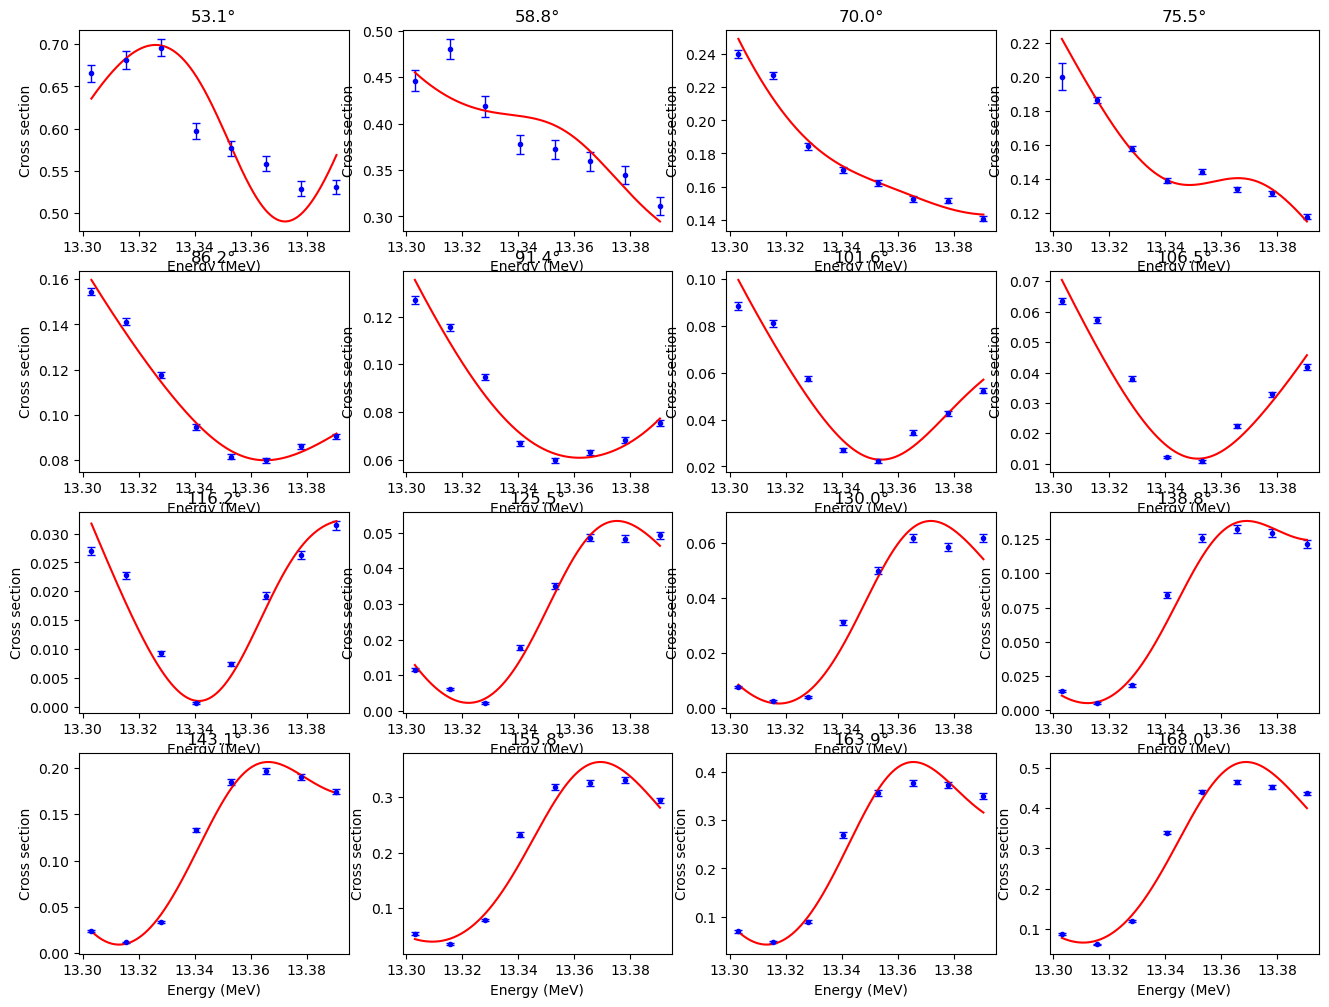

In [19]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(first_window, best_params, best_angular_momenta)

In [20]:
second_window = windows[1]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(second_window, cluster_energies, cluster_widths)

with open("top_fits_w2.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, second_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w2.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.8536e+11, final cost 3.6181e+04, first-order optimality 1.50e+03.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 3.4916e+11, final cost 1.8914e+05, first-order optimality 5.82e+05.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 2.9311e+11, final cost 4.2823e+04, first-order optimality 1.25e+04.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.3800e+11, final cost 6.1606e+04, first-order optimality 7.29e+04.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.2917e+11, final cost 8.1899e+04, first-order optimality 3.21e+04.
Progress: 13.9% (5/36)The maxim

Resonance 1: E_r = 13.439503 MeV, l = 2, Gamma = 0.090375 MeV
Resonance 2: E_r = 13.458504 MeV, l = 0, Gamma = 0.081443 MeV


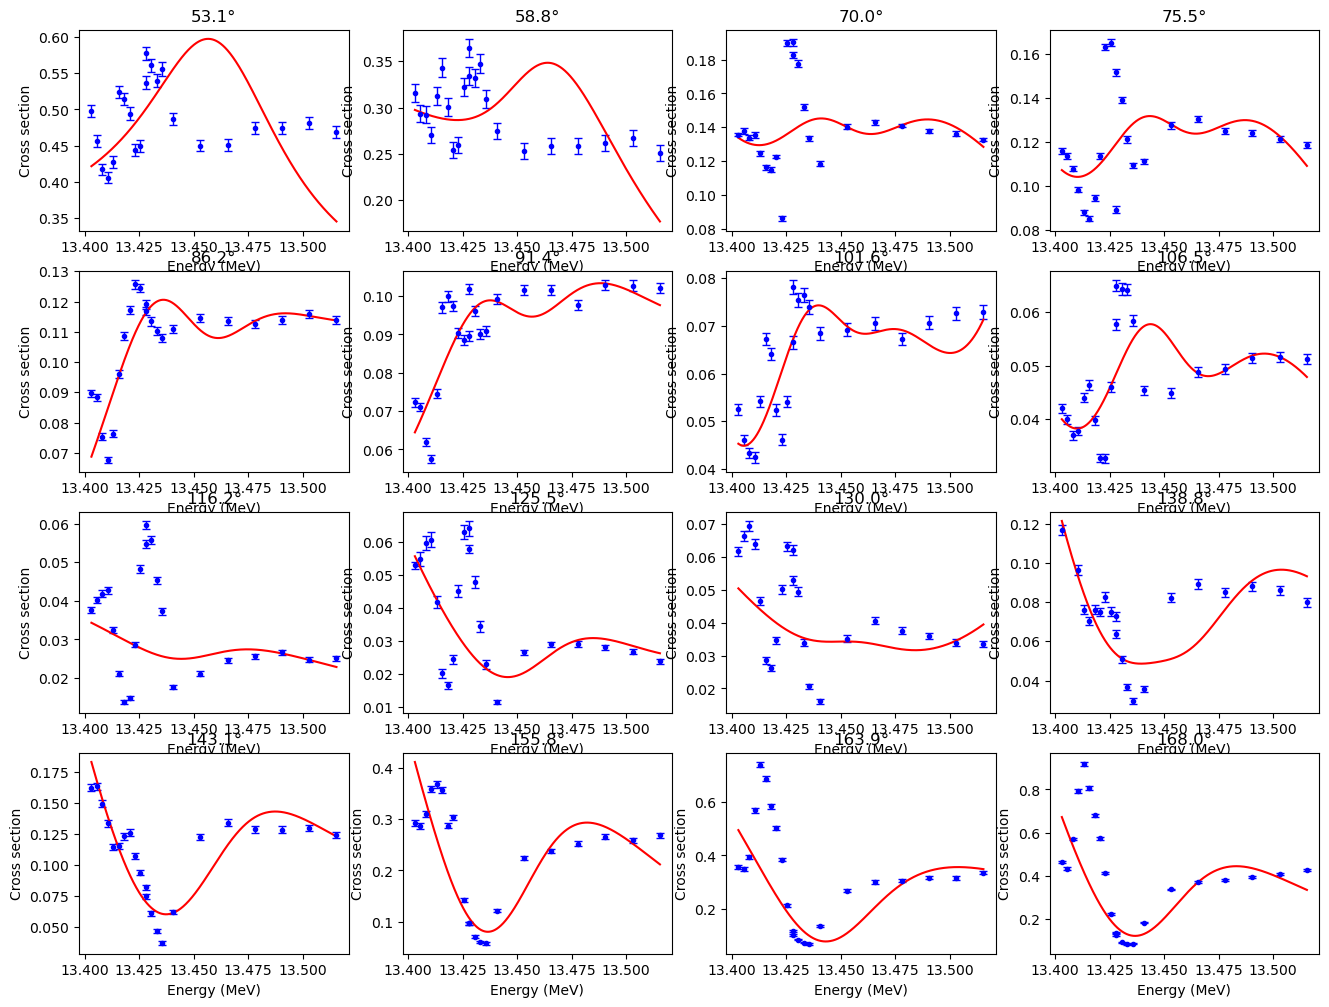

(2, 0)


In [21]:
best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(second_window, best_params, best_angular_momenta)
print(best_angular_momenta)

Initial parameters: (137,)
Lower bounds: (137,)
Upper bounds: (137,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.5401e+11, final cost 4.3461e+04, first-order optimality 1.47e+05.
Progress: 0.5% (1/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.6183e+11, final cost 4.7454e+04, first-order optimality 4.74e+03.
Progress: 0.9% (2/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.6797e+11, final cost 4.5835e+04, first-order optimality 7.99e+03.
Progress: 1.4% (3/216)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 4.5340e+11, final cost 3.9263e+04, first-order optimality 4.11e+03.
Progress: 1.9% (4/216)`xtol` termination condition is satisfied.
Function evaluations 67, initial cost 4.5780e+11, final cost 7.2077e+04, first-order optimality 5.12e+08.
Progress: 2.3% (5/216)The maximum number o

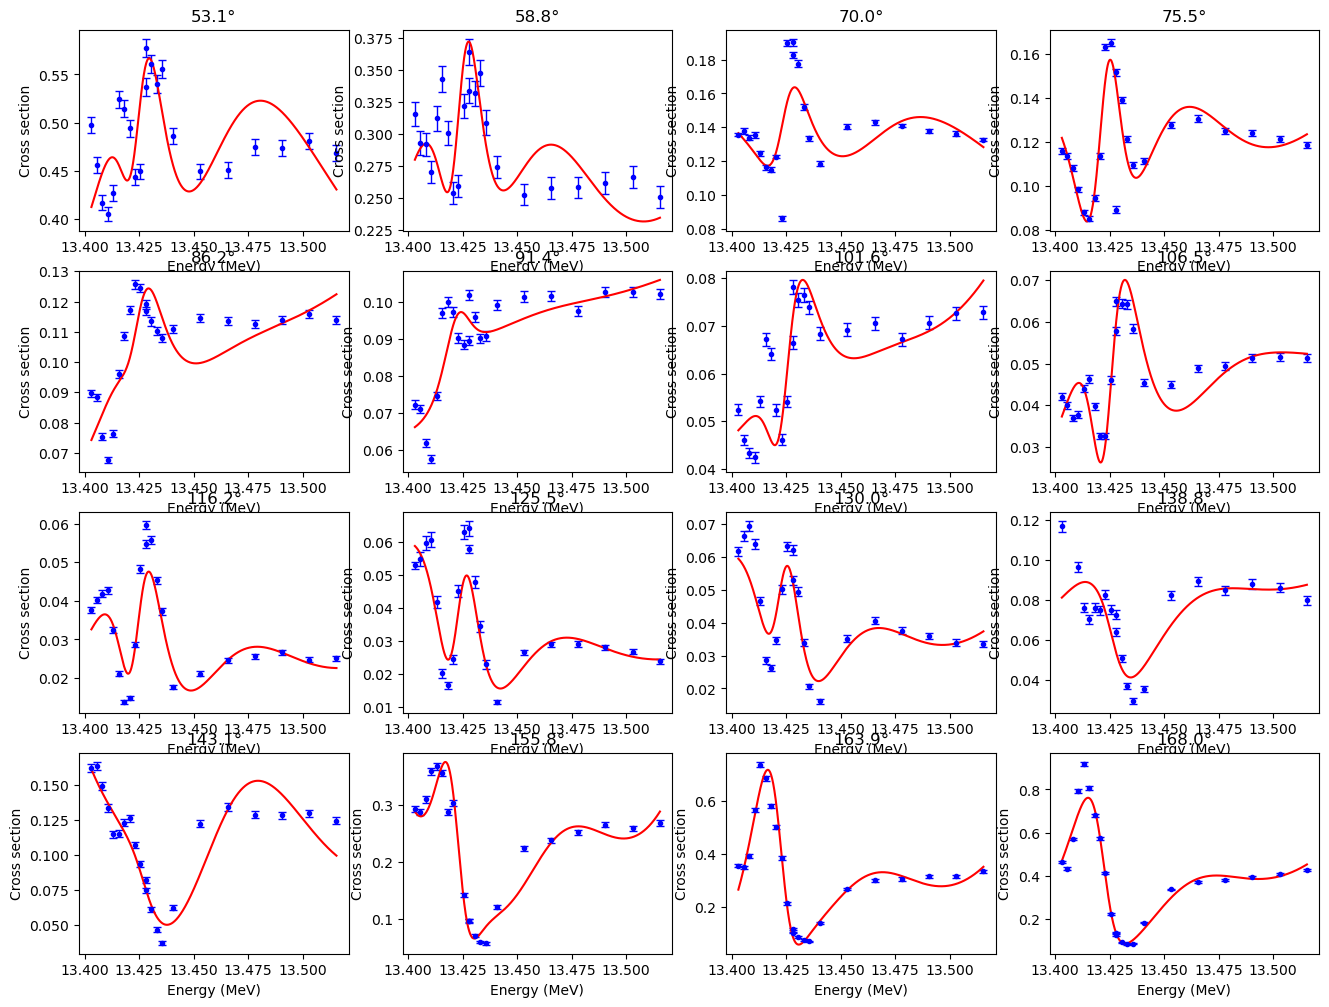

In [22]:
test_energies = np.append(cluster_energies, 13.41)
test_widths = np.append(cluster_widths, 0.005)

test_fits, test_lower_bound, test_upper_bound = scattering_model.fitting_routine_1(
    second_window,
    test_energies,
    test_widths
)

test_refined_fits = scattering_model.fitting_routine_2(test_fits, second_window, test_lower_bound, test_upper_bound)

test_best_fit_cost, test_best_angular_momenta, test_best_params = test_refined_fits[0]

scattering_model.get_fit_visual(second_window, test_best_params, test_best_angular_momenta)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3078e+11, final cost 2.4588e+03, first-order optimality 1.16e+04.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3522e+11, final cost 3.9990e+03, first-order optimality 2.51e+03.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3419e+11, final cost 3.2833e+03, first-order optimality 2.22e+03.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.2883e+11, final cost 2.0976e+03, first-order optimality 7.38e+01.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 1.3679e+11, final cost 2.8884e+03, first-order optimality 4.36e+03.
Progress: 13.9% (5/36)The maxim

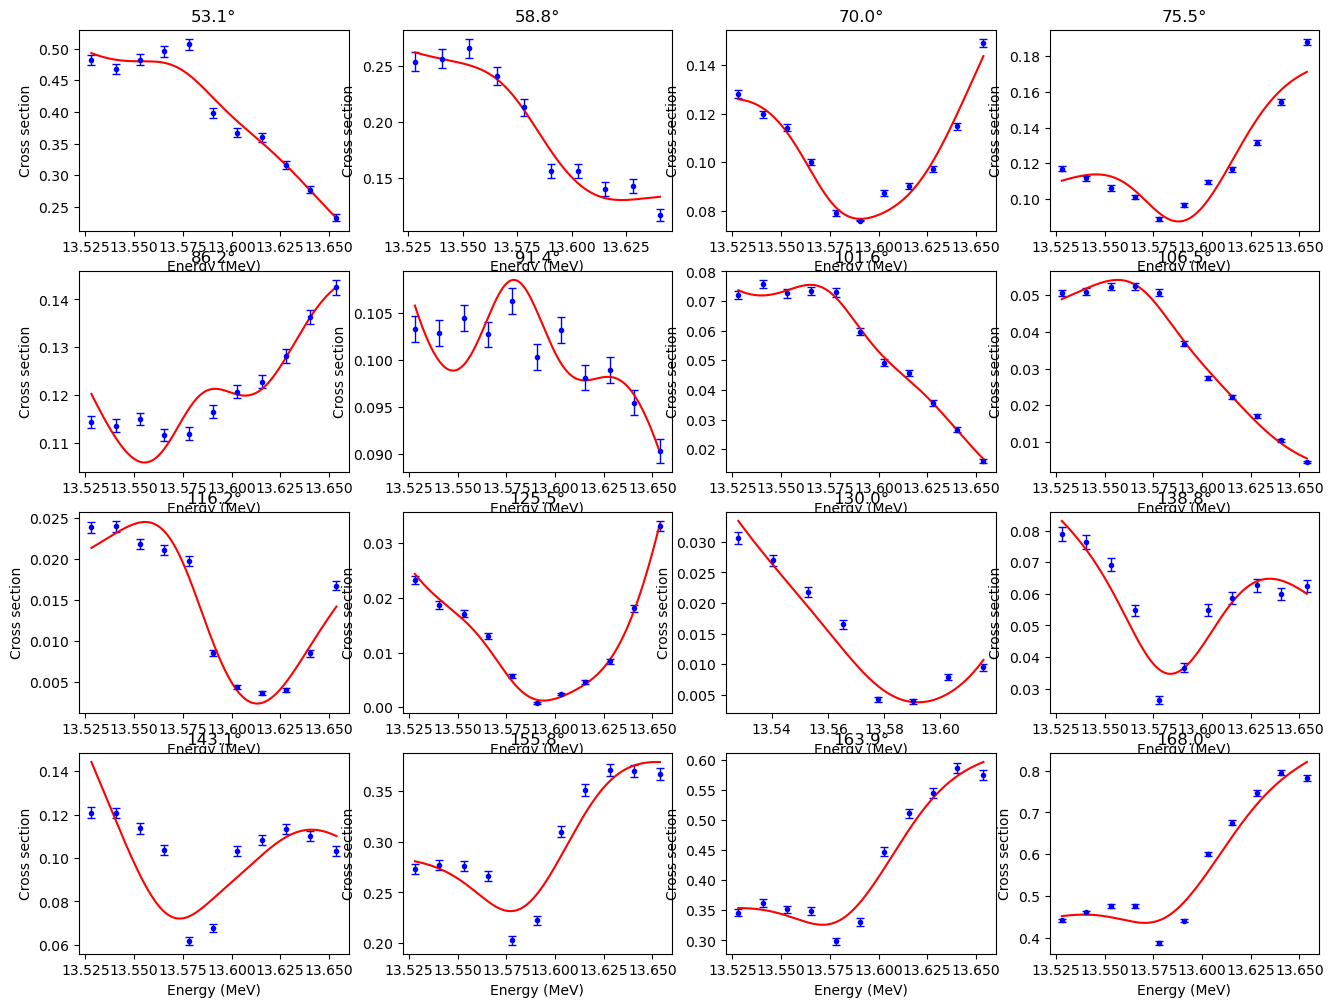

(0, 0)


In [23]:
third_window = windows[2]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(third_window, cluster_energies, cluster_widths)

with open("top_fits_w3.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, third_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w3.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(third_window, best_params, best_angular_momenta)
print(best_angular_momenta)

Initial parameters: (102,)
Lower bounds: (102,)
Upper bounds: (102,)
The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.3009e+11, final cost 9.7875e+03, first-order optimality 8.37e+03.
Progress: 2.8% (1/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.4378e+11, final cost 1.0577e+04, first-order optimality 2.68e+04.
Progress: 5.6% (2/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.4963e+11, final cost 1.8800e+04, first-order optimality 5.38e+03.
Progress: 8.3% (3/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.3883e+11, final cost 8.9931e+03, first-order optimality 9.51e+03.
Progress: 11.1% (4/36)The maximum number of function evaluations is exceeded.
Function evaluations 200, initial cost 8.4074e+11, final cost 6.9355e+04, first-order optimality 6.93e+04.
Progress: 13.9% (5/36)The maxim

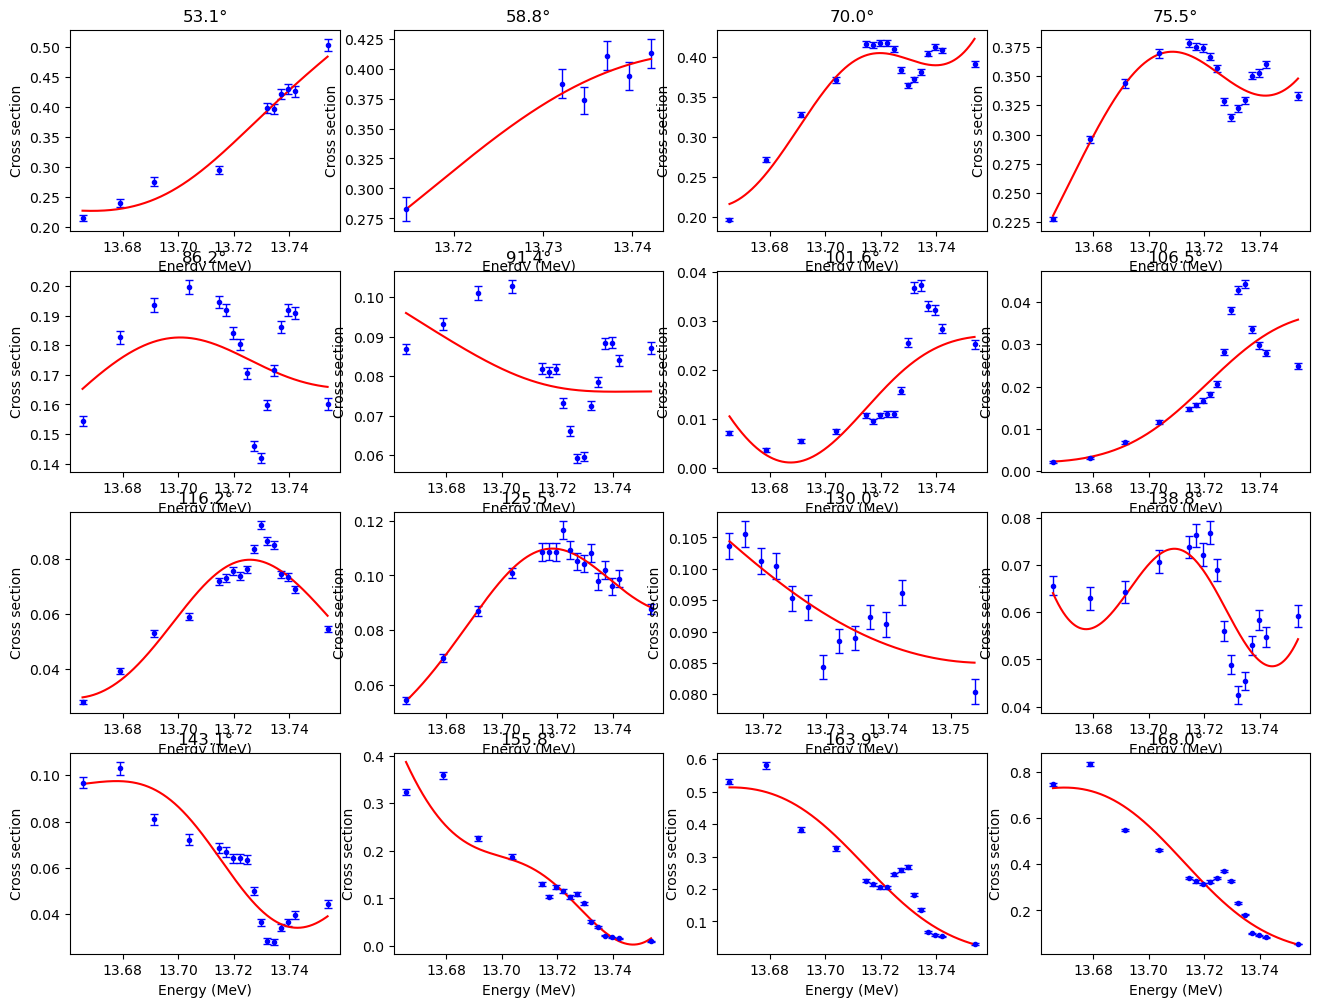

(1, 1)


In [24]:
fourth_window = windows[3]

fits, lower_bound, upper_bound = scattering_model.fitting_routine_1(fourth_window, cluster_energies, cluster_widths)

with open("top_fits_w3.pkl", "wb") as f:
    pickle.dump(fits, f)

refined_fits = scattering_model.fitting_routine_2(fits, fourth_window, lower_bound, upper_bound)

with open("top_10_refined_fits_w3.pkl", "wb") as f:
    pickle.dump(refined_fits, f)

best_fit_cost, best_angular_momenta, best_params = refined_fits[0]

scattering_model.get_fit_visual(fourth_window, best_params, best_angular_momenta)
print(best_angular_momenta)

In [39]:
angular_momenta = (0, 1)

result, bounds = differential_evolution_routine.de_fitting_routine(
    first_window,
    cluster_energies,
    angular_momenta,
    m_cap=5,
    c_cap=1,
    maxiter=1000
)

differential_evolution step 1: f(x)= 1998431.7169783039
differential_evolution step 2: f(x)= 1852848.500617533
differential_evolution step 3: f(x)= 1801157.2108198989
differential_evolution step 4: f(x)= 1801157.2108198989
differential_evolution step 5: f(x)= 1192407.2485124357
differential_evolution step 6: f(x)= 1192407.2485124357
differential_evolution step 7: f(x)= 1192407.2485124357
differential_evolution step 8: f(x)= 959654.4853871674
differential_evolution step 9: f(x)= 959654.4853871674
differential_evolution step 10: f(x)= 959654.4853871674
differential_evolution step 11: f(x)= 363651.9837208695
differential_evolution step 12: f(x)= 363651.9837208695
differential_evolution step 13: f(x)= 348549.20875541726
differential_evolution step 14: f(x)= 348549.20875541726
differential_evolution step 15: f(x)= 348549.20875541726
differential_evolution step 16: f(x)= 296414.1044358845
differential_evolution step 17: f(x)= 296414.1044358845
differential_evolution step 18: f(x)= 296414.104

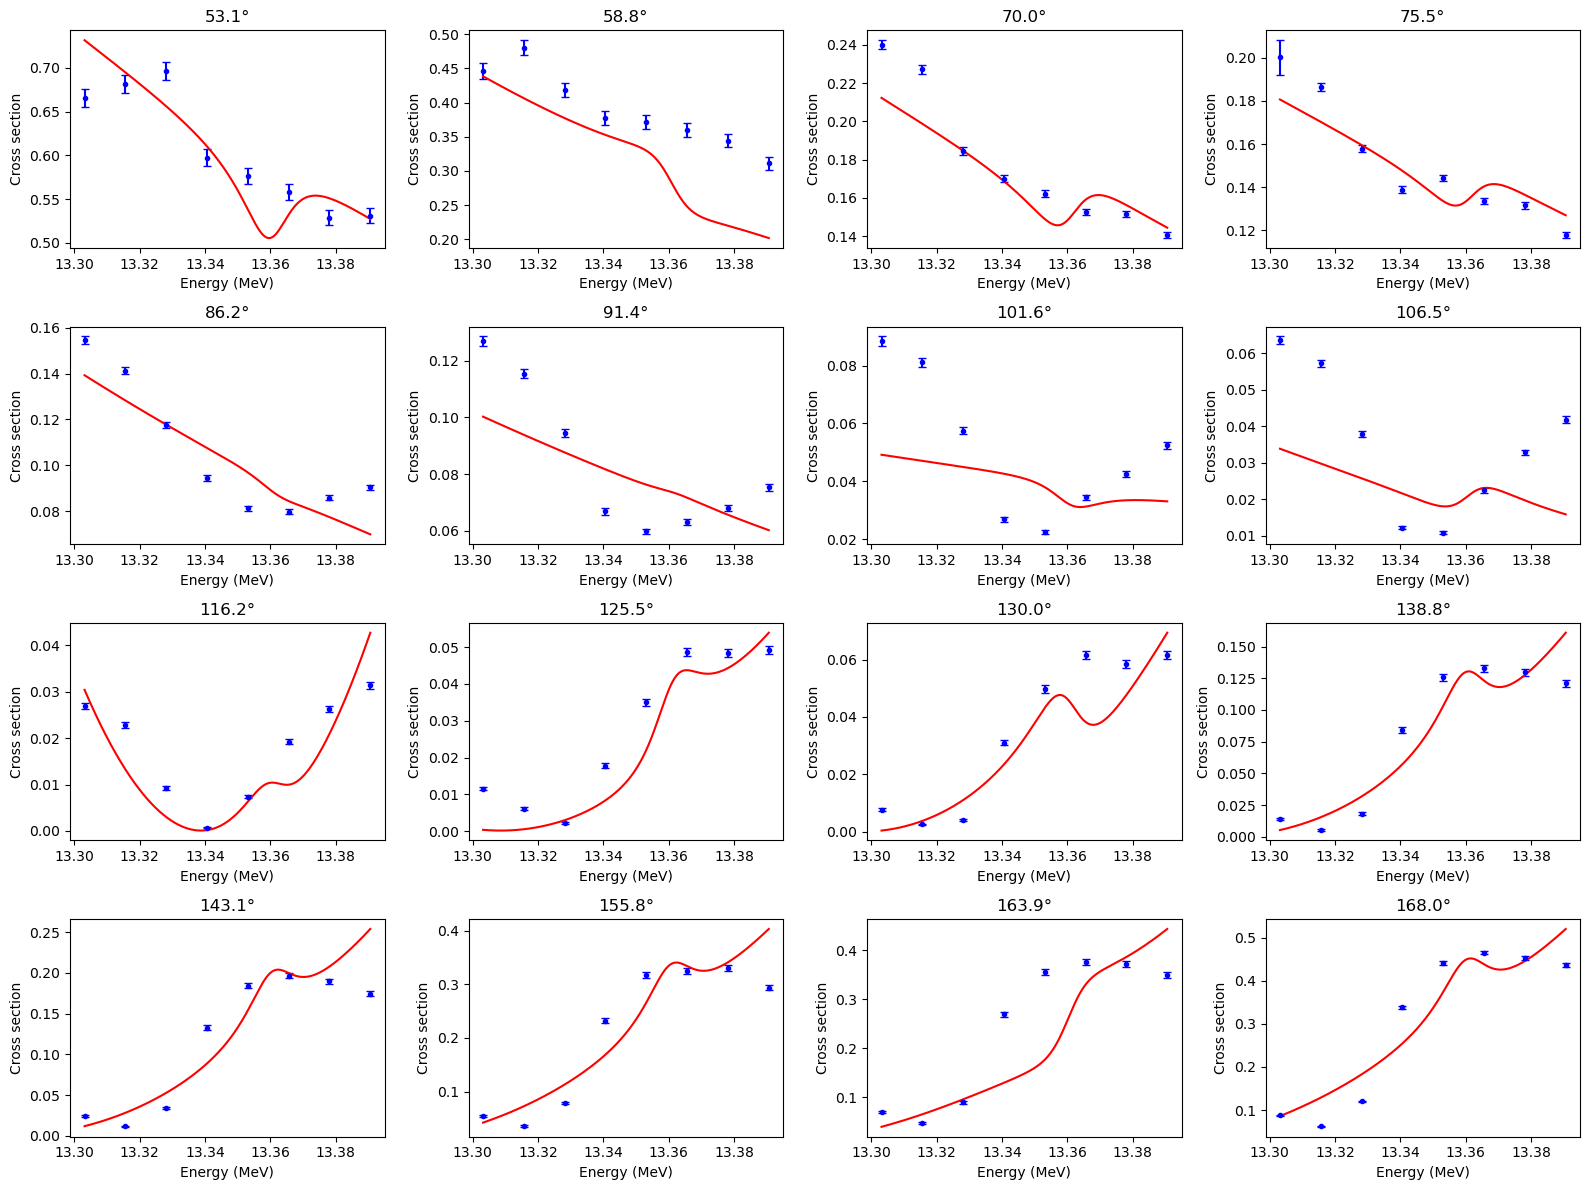

In [40]:
differential_evolution_routine.get_de_fit_visual(
    first_window, result.x, angular_momenta
)

In [42]:
resonances, backgrounds = scattering_model.parameters_to_dictionary(
    result.x, angular_momenta
)

for i, resonance in enumerate(resonances):
    print(f"\nResonance {i+1}")
    print("Angular momentum:", resonance["angular m"])
    print("Energy (MeV):", resonance["r energy"])
    print("Width (MeV):", resonance["width"])
    print("Width ratio:", resonance["p width ratio"])




Resonance 1
Angular momentum: 0
Energy (MeV): 13.317302251114857
Width (MeV): 0.8177278338985713
Width ratio: 0.00849542197359715

Resonance 2
Angular momentum: 1
Energy (MeV): 13.360777724316398
Width (MeV): 0.018485063517347022
Width ratio: 0.052118646298073


In [ ]:
print("Same window?", window is windows[0])

angle = next(iter(window))

print("Expected boundaries:", windows[0][angle]["E_min"],
                              windows[0][angle]["E_max"])

print("Plotted boundaries:", window[angle]["E_min"],
                             window[angle]["E_max"])

print("Plotted data range:", window[angle]["ke"].min(),
                             window[angle]["ke"].max())

In [ ]:
#testing

resonances = [
    {
        "angular m" : 2,
        "p width ratio" : 0.3,
        "width": 0.1,
        "r energy": 13,
        "a": 0.0,
        "b": 0.0
    },
    {
            "angular m" : 5,
            "p width ratio" : 0.2,
            "width": 2,
            "r energy": 18,
            "a": 0.0,
            "b": 0.0
        }
]

energy = np.linspace(10, 20, 1000)
theta = np.deg2rad(45)

sigma = scattering_model.model(
    theta,
    energy,
    resonances,
    m=0,
    c=0
)

import matplotlib.pyplot as plt

plt.plot(energy, sigma)

plt.xlabel("Centre-of-mass energy (MeV)")
plt.ylabel("Differential cross section (fm²/sr)")
plt.legend()
plt.show()

In [ ]:
for angle in [0, 30, 45, 60, 90]:
    sigma = scattering_model.model(
        np.deg2rad(angle),
        energy,
        resonances,
        m=0,
        c=0
    )

    plt.plot(energy, sigma, label=f"{angle}°")

plt.xlabel("Centre-of-mass energy (MeV)")
plt.ylabel("Differential cross section (fm²/sr)")
plt.legend()
plt.show()